# HYNET Task 3.2 reference test case — presentation

This notebook presents the `tx-full` variant of the common reference test case of HYNET
Task 3.2: the IEEE 39-bus and IEEE 14-bus systems joined by a VSC HVDC link, with four
bidding zones, three operating scenarios and two batteries.

It reads only the published files in `testcase/`. The load flows below are run live with
pypowsybl (OpenLoadFlow) to illustrate the operating points; they are not results of any
HYNET tool.

Schemas and conventions are documented in [`docs/test-case.md`](../docs/test-case.md) and
[`docs/data-dictionary.md`](../docs/data-dictionary.md).

In [1]:
import logging

# pypowsybl logs a notice about optional dependencies when it is first imported.
logging.getLogger("powsybl").setLevel(logging.ERROR)

import pandas as pd
import pypowsybl as pp
from IPython.display import SVG, display

from hynet_testcase.network.loadflow import run_ac
from hynet_testcase.paths import RepoPaths
from hynet_testcase.scenarios.report import branch_loadings, bus_voltages
from hynet_testcase.viz.plots import (
    ZONE_COLORS, plot_dispatch, plot_loadings, plot_voltage_profiles, plot_zone_balance,
    zone_diagram_parameters, zone_diagram_profile,
)

TX_FULL = RepoPaths.discover().testcase / "tx-full"


def read_csv(path):
    # Ids are read as text, never parsed as numbers.
    return pd.read_csv(TX_FULL / path, dtype={"generator_id": str, "load_id": str}, keep_default_na=False)

## 1. Network

In [2]:
network = pp.network.load(str(TX_FULL / "network/base/xiidm/tx-full_base.xiidm"))
bus_zones = read_csv("zones/bus_zones.csv")

voltage_levels = network.get_voltage_levels()
summary = pd.DataFrame({
    "buses": network.get_bus_breaker_view_buses()["voltage_level_id"].map(voltage_levels["nominal_v"]).value_counts(),
    "lines": network.get_lines()["voltage_level1_id"].map(voltage_levels["nominal_v"]).value_counts(),
    "transformers": network.get_2_windings_transformers()["voltage_level1_id"].map(voltage_levels["nominal_v"]).value_counts(),
    "generators": network.get_generators()["voltage_level_id"].map(voltage_levels["nominal_v"]).value_counts(),
    "loads": network.get_loads()["voltage_level_id"].map(voltage_levels["nominal_v"]).value_counts(),
    "batteries": network.get_batteries()["voltage_level_id"].map(voltage_levels["nominal_v"]).value_counts(),
}).fillna(0).astype(int).rename_axis("nominal voltage (kV)")
summary.index = summary.index.map({138.0: "138 kV (IEEE 14)", 345.0: "345 kV (IEEE 39)"})
summary

,buses,lines,transformers,generators,loads,batteries
nominal voltage (kV),,,,,,
138 kV (IEEE 14),14,18,3,5,11,1
345 kV (IEEE 39),39,34,12,10,31,1


### Network-area diagram

Buses are coloured by bidding zone; branch labels are active power flows (MW) of the base
case. The grey element between zones Z1 and Z0 is the HVDC link.

■ Z0 · ■ Z1 · ■ Z2 · ■ Z3

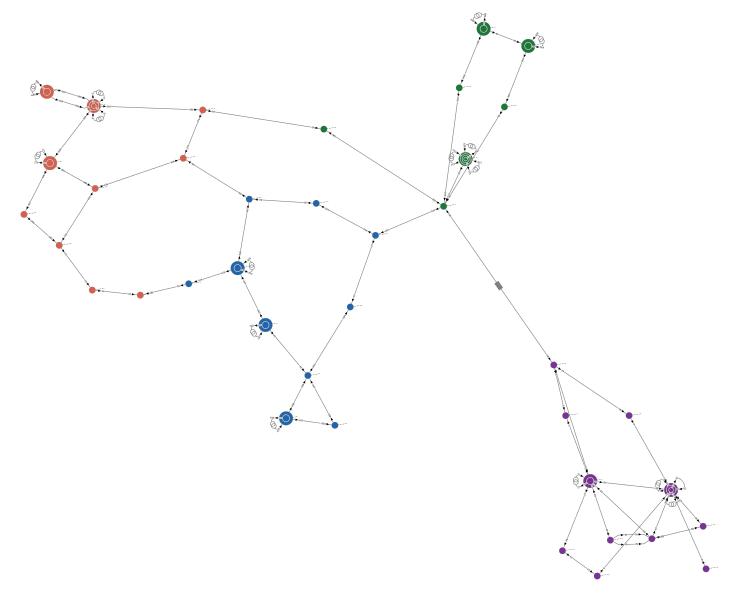

In [3]:
legend = " · ".join(f'<span style="color:{color}">■ {zone}</span>' for zone, color in ZONE_COLORS.items())
display({"text/html": legend}, raw=True)
display(SVG(network.get_network_area_diagram(
    nad_parameters=zone_diagram_parameters(),
    nad_profile=zone_diagram_profile(network, bus_zones)).svg))

### On the map

The same diagram with each bus at the coordinates of its substation
(`network/bus_coordinates.csv`): IEEE 14 in south-east England (Z0), and IEEE 39 in
northern France (Z1), Belgium (Z2) and the Netherlands (Z3), with the HVDC link across
the Strait of Dover. The coordinates are illustrative, not real substation sites.

■ Z0 · ■ Z1 · ■ Z2 · ■ Z3

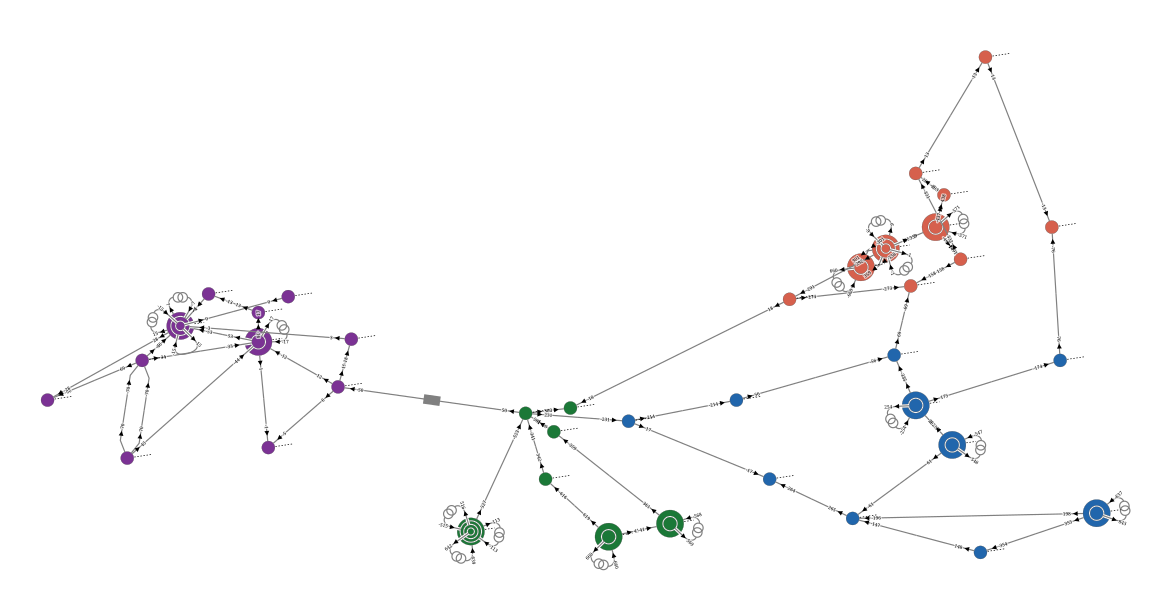

In [4]:
from pypowsybl.network import NadLayoutType

display({"text/html": legend}, raw=True)
display(SVG(network.get_network_area_diagram(
    nad_parameters=zone_diagram_parameters(NadLayoutType.GEOGRAPHICAL),
    nad_profile=zone_diagram_profile(network, bus_zones)).svg))

### Interactive explorer

The explorer below needs a live kernel (for example on Binder); it is not rendered on
GitHub. It opens on bus 16, where the HVDC link leaves IEEE 39; its map tab shows the
network at the substation coordinates.

In [5]:
from pypowsybl_jupyter import network_explorer

network_explorer(network, vl_id="VL16", depth=2)

## 2. Bidding zones

IEEE 14 forms zone Z0; IEEE 39 is split into its three classic areas Z1–Z3.

In [6]:
element_zones = read_csv("zones/element_zones.csv")
generators = read_csv("scenarios/generators.csv")
capacity = (element_zones[element_zones["element_type"] == "generator"]
            .merge(generators, left_on="element_id", right_on="generator_id")
            .groupby("zone_id")["nominal_p_mw"].sum())
pd.DataFrame({
    "buses": bus_zones["zone_id"].value_counts(),
    "generators": element_zones[element_zones["element_type"] == "generator"]["zone_id"].value_counts(),
    "loads": element_zones[element_zones["element_type"] == "load"]["zone_id"].value_counts(),
    "installed capacity (MW)": capacity,
}).sort_index()

,buses,generators,loads,installed capacity (MW)
zone_id,,,,
Z0,14,5,11,515.0
Z1,12,4,8,3202.0
Z2,13,3,10,2305.0
Z3,14,3,13,3045.0


In [7]:
read_csv("zones/interconnections.csv")

,interconnection_id,type,zone_from,zone_to,capacity_mw
0,L-1-39-1,ac_branch,Z2,Z3,999.7
1,L-14-15-1,ac_branch,Z3,Z1,599.9
2,L-16-17-1,ac_branch,Z1,Z2,599.9
3,L-3-4-1,ac_branch,Z2,Z3,500.2
4,HVDC_Link_16_113,hvdc,Z1,Z0,60.0


## 3. HVDC link

In [8]:
hvdc = network.get_hvdc_lines()[["converter_station1_id", "converter_station2_id", "converters_mode", "max_p", "nominal_v", "r"]]
hvdc

,converter_station1_id,converter_station2_id,converters_mode,max_p,nominal_v,r
id,,,,,,
HVDC_Link_16_113,VSC_Station_16,VSC_Station_113,SIDE_1_RECTIFIER_SIDE_2_INVERTER,60.0,320.0,0.75


In [9]:
read_csv("scenarios/hvdc.csv")

,timestamp,scenario_id,scenario_name,hvdc_line_id,target_p_mw
0,2025-01-01T00:00:00Z,S1,baseline,HVDC_Link_16_113,50.0
1,2025-01-01T01:00:00Z,S2,high_res_low_demand,HVDC_Link_16_113,60.0
2,2025-01-01T02:00:00Z,S3,low_res_high_demand,HVDC_Link_16_113,50.0


## 4. Scenarios

| Id | Name | Loads (P / Q) | RES output | HVDC |
|----|------|---------------|------------|------|
| S1 | `baseline` | × 1.00 / × 1.00 | 50 % | 50 MW |
| S2 | `high_res_low_demand` | × 0.70 / × 0.70 | 100 % | 60 MW (maximum) |
| S3 | `low_res_high_demand` | × 1.08 / × 1.50 | 10 % | 50 MW |

Non-RES units are dispatched in merit order within each AC island.

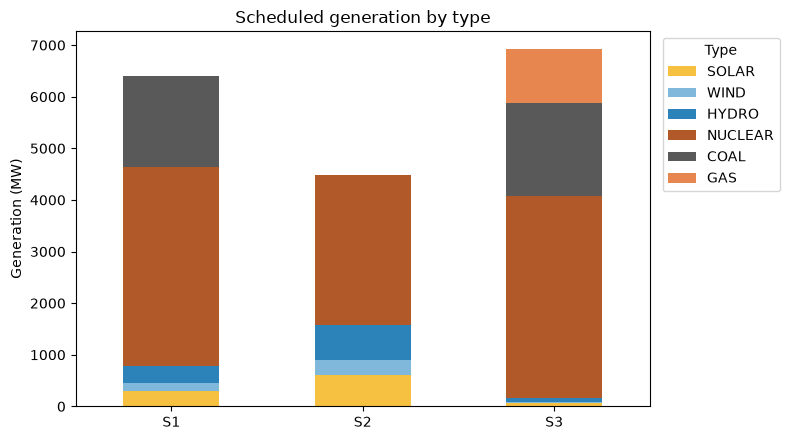

In [10]:
generation = read_csv("scenarios/generation.csv")
plot_dispatch(generation, generators);

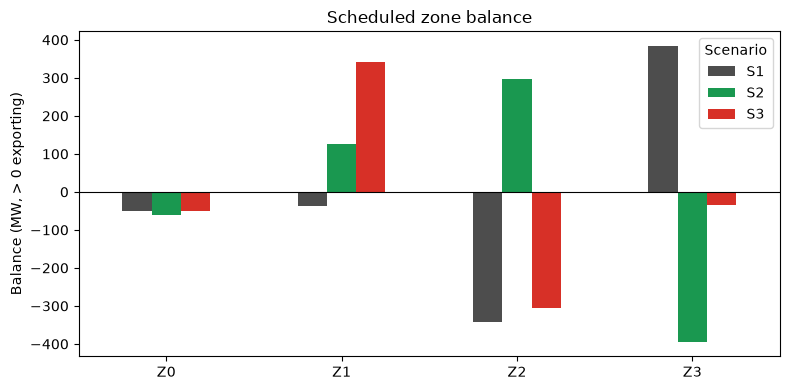

In [11]:
plot_zone_balance(read_csv("zones/zone_balance.csv"));

Economic assumptions, shared by every variant:

In [12]:
read_csv("economics/parameters.csv")

,parameter,value,unit,description
0,value_of_lost_load_eur_mwh,1.000000e+04,EUR/MWh,Cost of energy not served
1,battery_cycling_cost_eur_mwh,2.000000e+00,EUR/MWh,Battery wear cost per MWh discharged
2,redispatch_premium_eur_mwh,1.000000e+01,EUR/MWh,Redispatch price margin around marginal cost
3,discount_rate,5.000000e-02,-,Discount rate for annualising investments
4,asset_lifetime_years,4.000000e+01,year,Economic lifetime of network assets
5,capital_recovery_factor,5.827800e-02,1/year,Annuity factor from discount rate and lifetime
6,line_cost_345kv_eur_km,1.200000e+06,EUR/km,Investment cost of a single-circuit 345 kV ove...


## 5. Operating points

Each scenario snapshot is loaded and solved with an AC load flow (distributed slack in
proportion to the dispatched units), as the build does.

In [13]:
voltages, loadings = {}, {}
for scenario in ("S1", "S2", "S3"):
    snapshot = pp.network.load(str(TX_FULL / f"scenarios/snapshots/{scenario}/xiidm/tx-full_base_{scenario}.xiidm"))
    run_ac(snapshot, scenario)
    voltages[scenario] = bus_voltages(snapshot)
    loadings[scenario] = branch_loadings(snapshot)

### Voltage profiles

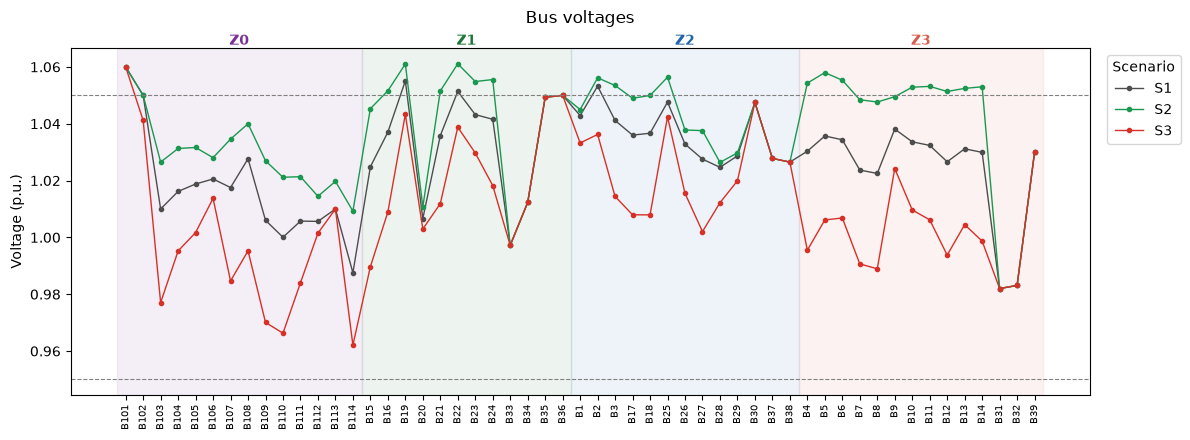

In [14]:
plot_voltage_profiles(voltages, bus_zones);

### Branch loadings

Every line and transformer has a permanent current limit; S3 is meant to stress them.

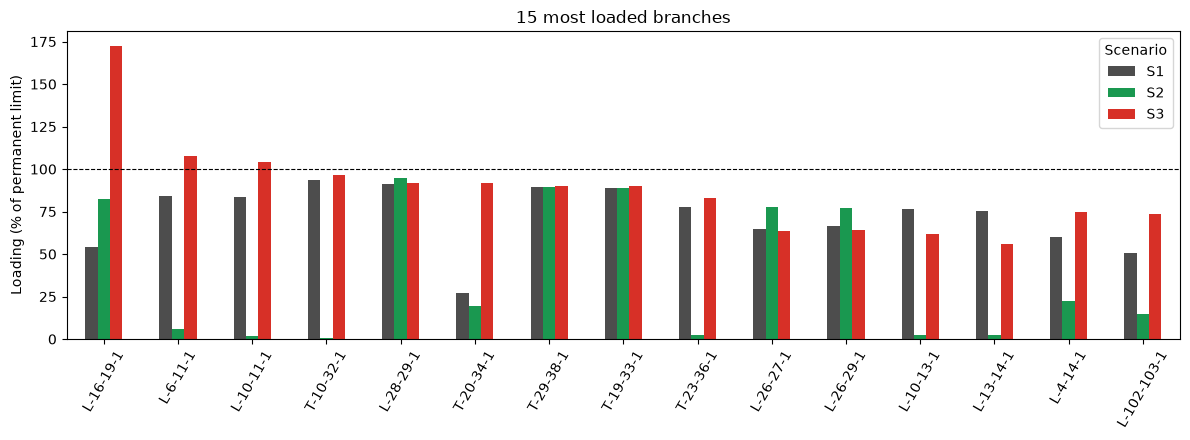

In [15]:
plot_loadings(loadings);

In [16]:
overloads = pd.DataFrame(loadings).rename_axis("branch")
overloads[(overloads > 100).any(axis=1)].round(0)

,S1,S2,S3
branch,,,
L-6-11-1,84.0,6.0,108.0
L-10-11-1,84.0,2.0,104.0
L-16-19-1,54.0,82.0,172.0


## 6. Contingencies

A small list of single outages (six lines, one generator, one transformer), none of
which splits the network. Each is applied to every scenario snapshot and solved with an
AC load flow; the table gives the highest branch loading (% of the permanent limit)
after the outage. A lost generator's output is taken up by the other units in proportion
to their output.

In [17]:
from hynet_testcase.network.contingencies import ContingencyList, summary_table

contingencies = ContingencyList.load(TX_FULL / "contingencies/contingencies.csv")
contingencies.table()

,contingency_id,element_type,element_id
0,N1-L-26-27,line,L-26-27-1
1,N1-L-26-29,line,L-26-29-1
2,N1-L-6-11,line,L-6-11-1
3,N1-L-21-22,line,L-21-22-1
4,N1-L-16-17,line,L-16-17-1
5,N1-L-104-105,line,L-104-105-1
6,N1-B38-G1,generator,B38-G1
7,N1-T-104-107,two_windings_transformer,T-104-107-1


In [18]:
post_contingency = {}
for scenario in ("S1", "S2", "S3"):
    snapshot = pp.network.load(str(TX_FULL / f"scenarios/snapshots/{scenario}/xiidm/tx-full_base_{scenario}.xiidm"))
    run_ac(snapshot, scenario)
    post_contingency[scenario] = contingencies.analyse(snapshot, scenario)
summary_table(post_contingency).round(0)

,S1,S2,S3
N1-L-26-27,111.0,134.0,176.0
N1-L-26-29,165.0,185.0,175.0
N1-L-6-11,162.0,95.0,187.0
N1-L-21-22,145.0,106.0,178.0
N1-L-16-17,93.0,95.0,173.0
N1-L-104-105,93.0,95.0,172.0
N1-B38-G1,119.0,143.0,244.0
N1-T-104-107,93.0,95.0,172.0


## 7. Reinforced case

The `reinforced` network case adds a second circuit parallel to L-26-27 (`L-26-27-2`,
same impedance and current limit). Its investment and annuity:

In [19]:
read_csv("economics/investments.csv")

,element_id,length_km,investment_eur,annuity_eur_year
0,L-26-27-2,58.3,69960000.0,4077140.16


The reinforced network is shipped without scenario states: the scenario set points
of `scenarios/` are applied to it, as a tool would. Highest branch loading after each
contingency (%), base and reinforced:

In [20]:
from hynet_testcase.ids import ScenarioId
from hynet_testcase.scenarios.inputs import ScenarioSnapshot

reinforced_post_contingency = {}
for scenario in ScenarioId:
    reinforced = pp.network.load(str(TX_FULL / "network/reinforced/xiidm/tx-full_reinforced.xiidm"))
    ScenarioSnapshot.from_testcase(TX_FULL / "scenarios", scenario).apply(reinforced)
    run_ac(reinforced, scenario)
    reinforced_post_contingency[str(scenario)] = contingencies.analyse(reinforced, scenario)
pd.concat({"base": summary_table(post_contingency),
           "reinforced": summary_table(reinforced_post_contingency)}, axis=1).round(0)

base               reinforced              
                 S1     S2     S3         S1     S2     S3
N1-L-26-27    111.0  134.0  176.0       93.0   95.0  172.0
N1-L-26-29    165.0  185.0  175.0      165.0  184.0  174.0
N1-L-6-11     162.0   95.0  187.0      162.0   95.0  188.0
N1-L-21-22    145.0  106.0  178.0      145.0  106.0  178.0
N1-L-16-17     93.0   95.0  173.0       93.0   95.0  173.0
N1-L-104-105   93.0   95.0  172.0       93.0   95.0  172.0
N1-B38-G1     119.0  143.0  244.0      120.0  142.0  243.0
N1-T-104-107   93.0   95.0  172.0       93.0   95.0  172.0

## 8. Batteries

Two batteries are part of the network models, idle (0 MW) in every snapshot so that
the tools decide their dispatch. Their power capability is in the network; their
energy capacity, efficiencies and states of charge are in `storage/batteries.csv`.

In [21]:
network.get_batteries(all_attributes=True)[["bus_breaker_bus_id", "min_p", "max_p", "min_q", "max_q", "target_p"]]

,bus_breaker_bus_id,min_p,max_p,min_q,max_q,target_p
id,,,,,,
BAT-B106-1,B106,-10.0,10.0,-10.0,10.0,0.0
BAT-B6-1,B6,-100.0,100.0,-100.0,100.0,0.0


In [22]:
read_csv("storage/batteries.csv")

,battery_id,bus_id,zone_id,power_mw,energy_mwh,charge_efficiency,discharge_efficiency,initial_soc,final_soc
0,BAT-B106-1,B106,Z0,10.0,20.0,0.95,0.95,0.5,0.5
1,BAT-B6-1,B6,Z3,100.0,200.0,0.95,0.95,0.5,0.5


In [23]:
read_csv("scenarios/battery_setpoints.csv")

,timestamp,scenario_id,scenario_name,battery_id,target_p_mw
0,2025-01-01T00:00:00Z,S1,baseline,BAT-B106-1,0.0
1,2025-01-01T00:00:00Z,S1,baseline,BAT-B6-1,0.0
2,2025-01-01T01:00:00Z,S2,high_res_low_demand,BAT-B106-1,0.0
3,2025-01-01T01:00:00Z,S2,high_res_low_demand,BAT-B6-1,0.0
4,2025-01-01T02:00:00Z,S3,low_res_high_demand,BAT-B106-1,0.0
5,2025-01-01T02:00:00Z,S3,low_res_high_demand,BAT-B6-1,0.0


## Not yet included

The reduced variant `tx-reduced` will be added in a later version.

---

<img src="../docs/assets/eu-emblem.svg" alt="Flag of the European Union" height="40">

HYNET project has received funding from the European Union's Horizon Europe research and
innovation programme under Grant Agreement No 101172757.